# Task 5: SalaryInsight - Random Forest Classifier
Train a Random Forest, tune hyperparameters, check feature importance and prevent overfitting using pruning.

## Step 1: Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

## Step 2: Load the data

In [2]:
df = pd.read_csv("employee_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (2000, 12)


,Age,Department,Education,City_Tier,Experience_Years,Performance_Rating,Weekly_Hours,Training_Hours,Certifications,Work_Life_Balance,Salary_LPA,Satisfaction
0,41,Marketing,PhD,Tier2,17,2.4,42.0,56.0,0,5.0,25.00,High
1,39,Sales,Bachelors,Tier1,13,3.7,49.0,12.0,2,3.1,19.41,Low
2,24,Operations,Diploma,Tier3,2,3.5,45.0,8.0,2,3.9,8.41,Low
3,26,Finance,Masters,Tier1,0,3.7,34.0,5.0,1,4.0,19.83,Low
4,44,Engineering,Bachelors,Tier2,19,3.8,40.0,56.0,0,3.2,28.35,High


## Step 3: Check and fix missing values
Performance_Rating and Training_Hours have some missing values. I will fill them with the median.

In [3]:
print(df.isnull().sum())

Age                    0
Department             0
Education              0
City_Tier              0
Experience_Years       0
Performance_Rating    25
Weekly_Hours           0
Training_Hours        25
Certifications         0
Work_Life_Balance      0
Salary_LPA             0
Satisfaction           0
dtype: int64


In [4]:
df["Performance_Rating"] = df["Performance_Rating"].fillna(df["Performance_Rating"].median())
df["Training_Hours"] = df["Training_Hours"].fillna(df["Training_Hours"].median())

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


## Step 4: Convert text columns into numbers
The target is `Satisfaction` (High = 1, Low = 0). Department, Education and City_Tier are text, so I use `get_dummies`.

In [5]:
df["Satisfaction"] = df["Satisfaction"].map({"Low": 0, "High": 1})
df = pd.get_dummies(df, columns=["Department", "Education", "City_Tier"], drop_first=True)
df.head()

,Age,Experience_Years,Performance_Rating,Weekly_Hours,Training_Hours,Certifications,Work_Life_Balance,Salary_LPA,Satisfaction,Department_Finance,Department_HR,Department_Marketing,Department_Operations,Department_Sales,Education_Diploma,Education_Masters,Education_PhD,City_Tier_Tier2,City_Tier_Tier3
0,41,17,2.4,42.0,56.0,0,5.0,25.00,1,False,False,True,False,False,False,False,True,True,False
1,39,13,3.7,49.0,12.0,2,3.1,19.41,0,False,False,False,False,True,False,False,False,False,False
2,24,2,3.5,45.0,8.0,2,3.9,8.41,0,False,False,False,True,False,True,False,False,False,True
3,26,0,3.7,34.0,5.0,1,4.0,19.83,0,True,False,False,False,False,False,True,False,False,False
4,44,19,3.8,40.0,56.0,0,3.2,28.35,1,False,False,False,False,False,False,False,False,True,False


## Step 5: Split into train and test data

In [6]:
X = df.drop("Satisfaction", axis=1)
y = df["Satisfaction"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 1600
Testing rows: 400


## Step 6: Basic Random Forest (no tuning)
By default the trees grow fully, so the model may overfit.

In [7]:
rf_basic = RandomForestClassifier(random_state=42)
rf_basic.fit(X_train, y_train)

basic_train_acc = accuracy_score(y_train, rf_basic.predict(X_train))
basic_test_acc = accuracy_score(y_test, rf_basic.predict(X_test))

print("Train accuracy:", round(basic_train_acc, 4))
print("Test accuracy :", round(basic_test_acc, 4))
print("Gap:", round(basic_train_acc - basic_test_acc, 4))

Train accuracy: 1.0
Test accuracy : 0.8375
Gap: 0.1625


Train accuracy is 100% but test accuracy is lower, so the basic model is **overfitting**.

## Step 7: Hyperparameter tuning with GridSearchCV
`max_depth`, `min_samples_leaf` and `ccp_alpha` limit or prune the trees so the model does not memorize the training data.

In [8]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": [1, 5, 10],
    "ccp_alpha": [0.0, 0.001, 0.005],   # pruning strength
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

Best parameters: {'ccp_alpha': 0.001, 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV accuracy: 0.835


## Step 8: Check the tuned (pruned) model

In [9]:
best_rf = grid.best_estimator_

tuned_train_acc = accuracy_score(y_train, best_rf.predict(X_train))
tuned_test_acc = accuracy_score(y_test, best_rf.predict(X_test))

compare = pd.DataFrame({
    "Model": ["Basic RF", "Tuned RF"],
    "Train Accuracy": [basic_train_acc, tuned_train_acc],
    "Test Accuracy": [basic_test_acc, tuned_test_acc],
})
compare["Gap"] = compare["Train Accuracy"] - compare["Test Accuracy"]
compare.round(4)

,Model,Train Accuracy,Test Accuracy,Gap
0,Basic RF,1.0000,0.8375,0.1625
1,Tuned RF,0.9662,0.8300,0.1363


## Step 9: Feature importance

In [10]:
importances = pd.Series(best_rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)
importances.head(10).round(4)

Salary_LPA            0.2503
Work_Life_Balance     0.2497
Age                   0.0871
Experience_Years      0.0826
Weekly_Hours          0.0811
Performance_Rating    0.0728
Training_Hours        0.0622
Certifications        0.0286
City_Tier_Tier2       0.0163
City_Tier_Tier3       0.0098
dtype: float64

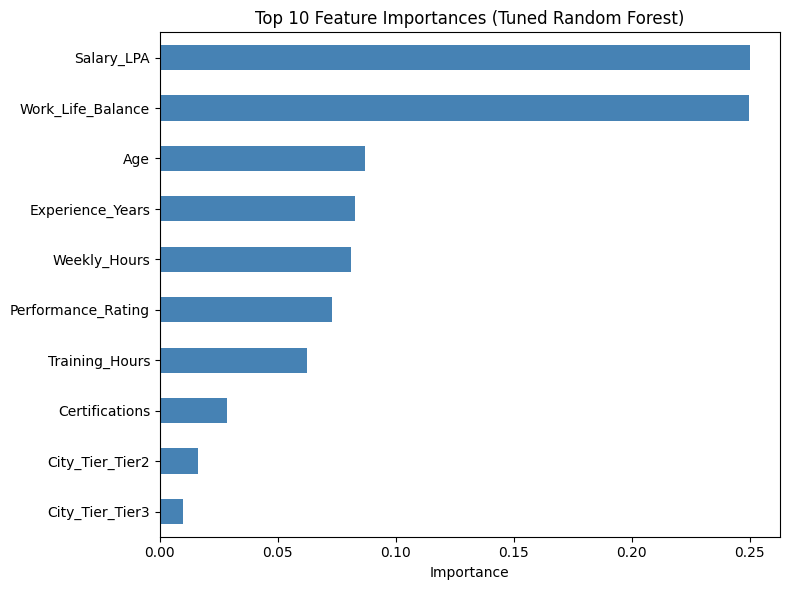

In [11]:
plt.figure(figsize=(8, 6))
importances.head(10).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Feature Importances (Tuned Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Step 10: Overfitting vs pruning (tree depth)
I train models with different `max_depth` values and compare train and test accuracy.

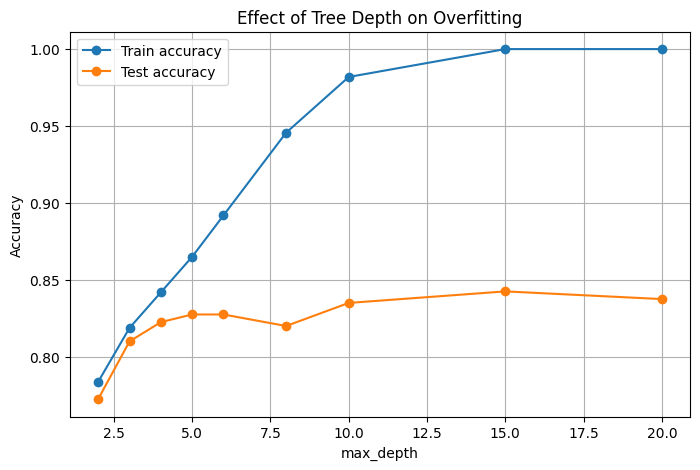

In [12]:
depths = [2, 3, 4, 5, 6, 8, 10, 15, 20]
train_scores = []
test_scores = []

for d in depths:
    model = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker="o", label="Train accuracy")
plt.plot(depths, test_scores, marker="o", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Effect of Tree Depth on Overfitting")
plt.legend()
plt.grid(True)
plt.show()

## Conclusion
- The basic Random Forest overfits (100% train accuracy vs about 84% test accuracy).
- Tuning with pruning settings reduces the train-test gap a little, but test accuracy stays around 83%.
- `Salary_LPA` and `Work_Life_Balance` are the most important features.